# BBO photon polarization tomography
## Problem
Recover a complex positive two-photon density matrix and the common count scale from an experimental polarization acquisition. The source uses two adjacent BBO crystals, a351nm pump and702nm photon pairs. Nine two-arm analyzer settings produce36 outcomes with four detectors. The source manuscript is Altepeter, James & Kwiat(2004), Fig7.

This notebook actively reconstructs all36 observations with the cleaned modules. No independent measured density truth exists. The historical near-Bell state and the original code result are distinct from truth; the ideal state is used only for a labeled physical characterization.

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.physics_model import predict
from src.solvers import reconstruct,linear_reconstruct
from src.visualization import comparison_figure
counts,projectors=load_data(ROOT/'data/raw_data.npz')
print('Measured count shape:',counts.shape,'projector shape:',projectors.shape)
print('Data range:',counts.min(),counts.max(),'count units')

Measured count shape: (36,) projector shape: (36, 4, 4)
Data range: 150.0 40230.0 count units


## Data
These are the actual table values, already corrected for accidentals and renormalized for detector efficiencies. They are therefore **author-real-processed** data, not raw independent Poisson samples. The known analyzer projectors are instrument conventions. No ideal density, expected Bell sign, or target-derived calibration is input to reconstruction.

The arrays use analyzer order H,V,D,A,R,L in each arm, row-major. A setting comprises one orthogonal pair per arm; the four corresponding outcomes should sum to the common scale in a stationary ideal experiment. Their observed differences diagnose residual drift/correction effects. Absolute exposure duration and a full correction covariance are not available.

In [2]:
names=['H','V','D','A','R','L']
groups=np.array([[counts.reshape(6,6)[i:i+2,j:j+2].sum() for j in (0,2,4)] for i in (0,2,4)])
print('Corrected totals per joint basis:')
print(groups)
print('Relative spread in setting totals:',np.ptp(groups)/np.mean(groups))
print('Hermitian design rank:',np.linalg.matrix_rank(projectors.reshape(36,16)))

Corrected totals per joint basis:
[[79694. 79095. 79955.]
 [78901. 78702. 78925.]
 [79640. 79189. 78983.]]
Relative spread in setting totals: 0.015814406156918398
Hermitian design rank: 16


## Physics
For normalized state $\rho$ and count scale $s$, the predicted outcome is $\mu_j=s\mathrm{Re}\mathrm{tr}(P_j\rho)$. The projector is $P_j=|a_jb_j\rangle\langle a_jb_j|$. Density axes are HH,HV,VH,VV. Circular conventions are $R=(H+iV)/\sqrt2$, $L=(H-iV)/\sqrt2$. A conjugation changes observable circular correlations; it is not an admissible alignment.

Physical states are Hermitian, positive semidefinite and unit trace. The complete set spans16 real Hermitian degrees of freedom including the overall scale. Removing circular analyzers removes sensitivity to certain imaginary coherences. This acquisition recovers a finite quantum-state representation, not a spatial image.

## Method
The positive model uses $R=TT^\dagger$, $\rho=R/\mathrm{tr}(R)$ and $s=\mathrm{tr}(R)$ with a complex lower-triangular $T$. Sixteen real coordinates cover its diagonal and off-diagonal entries. The objective is $\sum_j(\max(\mu_j,0.01)-c_j)^2/\max(\mu_j,0.01)$, where $c_j$ denotes corrected observations. Initialization is the maximally mixed state with the original small coordinate perturbation; MINPACK Levenberg–Marquardt uses the original stopping settings.

This preserves the original KwiatLab implementation. It is a Pearson-like approximation, not an exact noise likelihood for corrected counts. We also actively compute unconstrained linear inversion, the16-outcome H/V/D/R subset and a no-circular diagnostic. These comparisons show positivity and measurement completeness, rather than replacing missing results with ideal references.

In [3]:
started=time.perf_counter()
rho,scale,diagnostics=reconstruct(counts,projectors)
elapsed=time.perf_counter()-started
linear,lscale=linear_reconstruct(counts,projectors)
selected=np.array([6*i+j for i in (0,1,2,4) for j in (0,1,2,4)])
partial,pscale,pdiag=reconstruct(counts[selected],projectors[selected])
solutions={'Full MLE':(rho,scale),'Linear inversion':(linear,lscale),'16-outcome MLE':(partial,pscale)}
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as upstream:
    oracle=upstream['output_density'].copy()
    oracle_scale=float(upstream['output_intensity'])
print('Fresh full reconstruction seconds:',elapsed)
print('Original-run distance:',np.linalg.norm(rho-oracle))
print('Scale:',scale,'Original:',oracle_scale,'Diagnostics:',diagnostics)
print('Linear minimum eigenvalue:',np.linalg.eigvalsh(linear).min())

Fresh full reconstruction seconds: 0.0547983999713324
Original-run distance: 0.0
Scale: 79259.40841883626 Original: 79259.40841883626 Diagnostics: {'objective': 501.3468431122622, 'evaluations': 589, 'status': 1}
Linear minimum eigenvalue: -0.029628587403381635


## Results
All comparisons below were computed above. The original-run reference is used solely for numerical parity. The measured setting totals vary; residuals therefore reflect a fixed common-scale modeling limitation. We do not interpret the objective divided by degrees of freedom as evidence of shot-noise-limited accuracy.

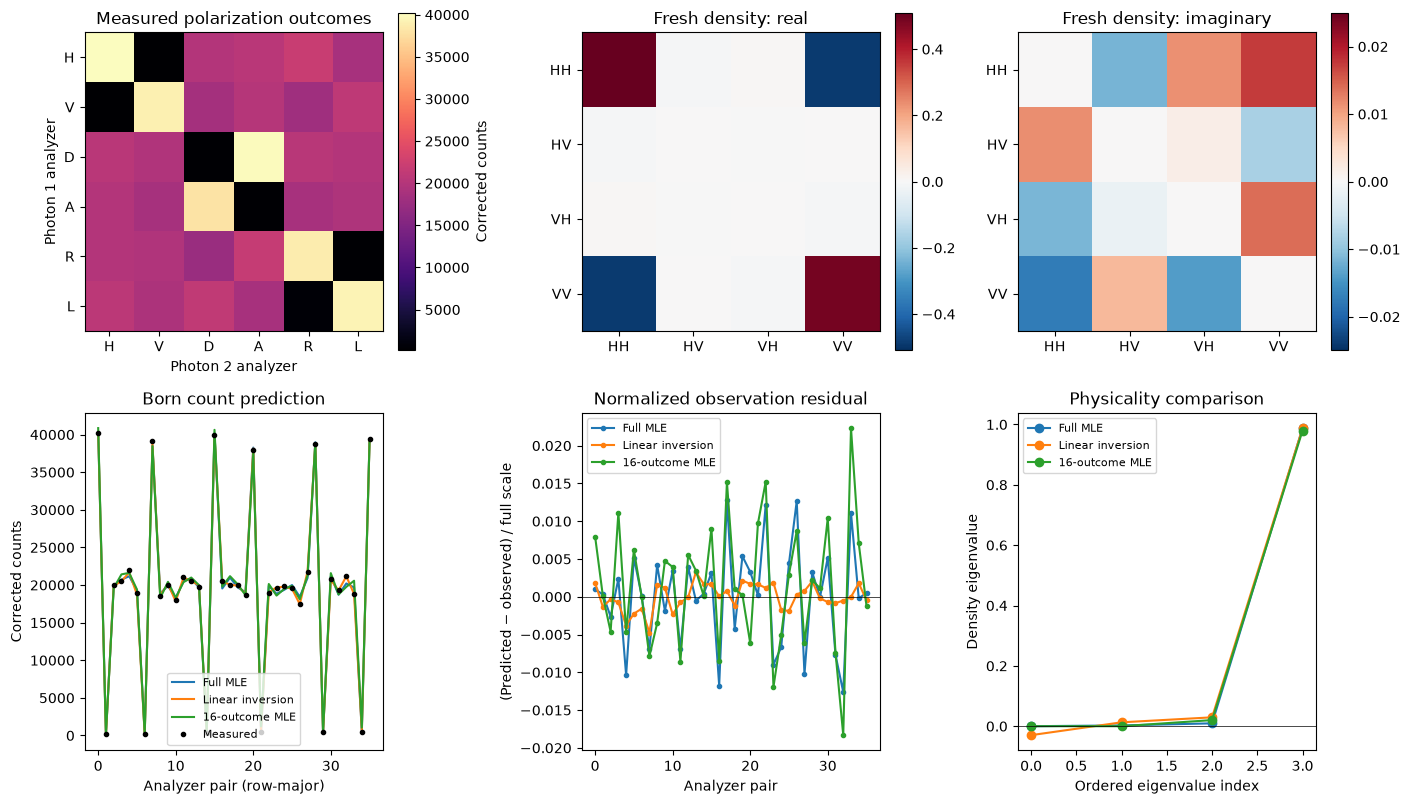

method | Frobenius distance to original | observation RMSE / scale | minimum eigenvalue
Full MLE 0.0 0.006664358465880508 5.40224290061836e-11
Linear inversion 0.038507278941118474 0.0017464064447085801 -0.029628587403381635
16-outcome MLE 0.02085326380659657 0.008436294262409005 1.1978809829412839e-09
Fresh overlap with ideal Bell state (NOT truth): 0.9868360961331987
Historical manuscript ideal-state overlap:0.9868; printed matrix precision~.001


In [4]:
fig=comparison_figure(counts,projectors,solutions)
plt.show()
print('method | Frobenius distance to original | observation RMSE / scale | minimum eigenvalue')
for label,(r,s) in solutions.items():
    print(label,np.linalg.norm(r-oracle),np.sqrt(np.mean((predict(r,projectors,s)-counts)**2))/s,np.linalg.eigvalsh(r).min())
ideal=np.array([1,0,0,-1],complex)/np.sqrt(2)
print('Fresh overlap with ideal Bell state (NOT truth):',np.real(ideal.conj()@rho@ideal))
print('Historical manuscript ideal-state overlap:0.9868; printed matrix precision~.001')

No circular analyzer design rank: 9 of16
No circular fit full-data normalized RMSE: 0.02211662244057443


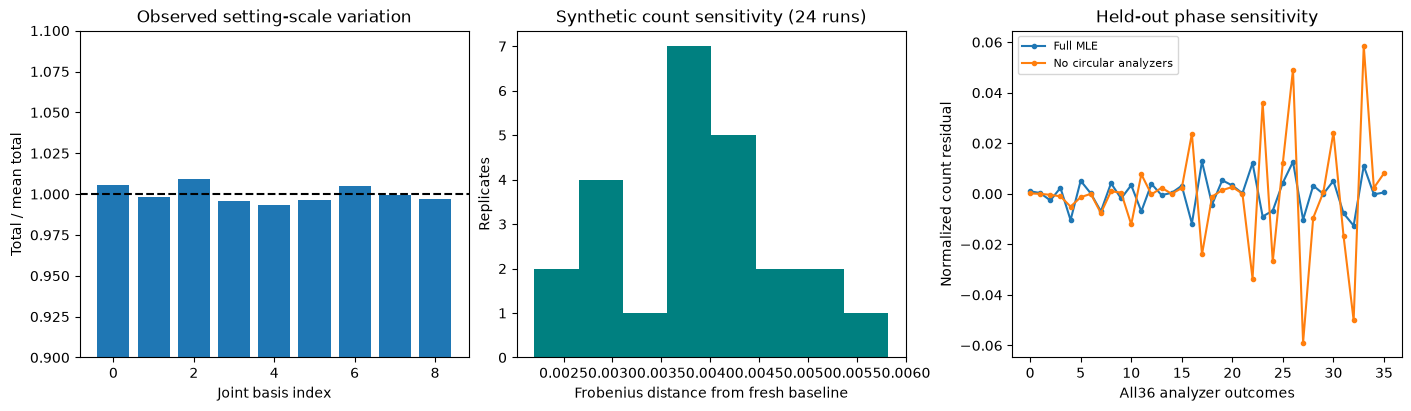

Supplementary distance range: 0.0022027288677789877 0.005819475481472639
Poisson perturbations are illustrative, not a validated experimental confidence interval.


In [5]:
# Supplementary perturbation analysis: synthetic resamples, not benchmark observations.
rng=np.random.default_rng(221)
distances=[];overlaps=[]
for _ in range(24):
    c=rng.poisson(counts).astype(float)
    r,s,_=reconstruct(c,projectors)
    distances.append(np.linalg.norm(r-rho))
    overlaps.append(np.real(ideal.conj()@r@ideal))
no_circular=np.array([6*i+j for i in range(4) for j in range(4)])
design=projectors[no_circular].reshape(16,16)
nr,ns,nd=reconstruct(counts[no_circular],projectors[no_circular])
print('No circular analyzer design rank:',np.linalg.matrix_rank(design),'of16')
print('No circular fit full-data normalized RMSE:',np.sqrt(np.mean((predict(nr,projectors,ns)-counts)**2))/ns)
fig2,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
axes[0].bar(np.arange(9),groups.ravel()/np.mean(groups));axes[0].axhline(1,color='k',ls='--');axes[0].set(title='Observed setting-scale variation',xlabel='Joint basis index',ylabel='Total / mean total',ylim=(.9,1.1))
axes[1].hist(distances,bins=8,color='teal');axes[1].set(title='Synthetic count sensitivity (24 runs)',xlabel='Frobenius distance from fresh baseline',ylabel='Replicates')
for r,s,label in [(rho,scale,'Full MLE'),(nr,ns,'No circular analyzers')]:axes[2].plot((predict(r,projectors,s)-counts)/s,'.-',label=label)
axes[2].set(title='Held-out phase sensitivity',xlabel='All36 analyzer outcomes',ylabel='Normalized count residual');axes[2].legend(fontsize=8)
plt.show()
print('Supplementary distance range:',min(distances),max(distances))
print('Poisson perturbations are illustrative, not a validated experimental confidence interval.')

In [6]:
from src.visualization import state_metrics
print('Fresh paper-characterization metrics:',state_metrics(rho))
print('Historical Fig7c values: tangle .9519; entropy .1033; linear entropy .0318; ideal overlap .9868.')
print('Historical uncertainties are not reused as new experimental errors.')

Fresh paper-characterization metrics: {'tangle': 0.9519358057322601, 'entropy_bits': 0.10308742893296498, 'linear_entropy': 0.03180797828888515, 'ideal_Bell_overlap': 0.9868360961331987}
Historical Fig7c values: tangle .9519; entropy .1033; linear entropy .0318; ideal overlap .9868.
Historical uncertainties are not reused as new experimental errors.


In [7]:
# Evaluate the fresh submission with the independent standalone judge.
import importlib.util
spec=importlib.util.spec_from_file_location('judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=rho[None],intensity=np.array([[scale]]))
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz')
print(json.dumps(report,indent=2))
assert exit_code==0
# Maintainer review artifacts outside the task; optional destination explicitly provided.
import os
if 'IMAGING_REVIEW_DIR' in os.environ:
    dest=Path(os.environ['IMAGING_REVIEW_DIR']);dest.mkdir(parents=True,exist_ok=True)
    fig.savefig(dest/'quantum_comparisons.png',dpi=150)
    fig2.savefig(dest/'quantum_sensitivity.png',dpi=150)
    (dest/'quantum_notebook_measurements.json').write_text(json.dumps({'seconds':elapsed,'objective':diagnostics['objective'],'count_scale':scale,'linear_min_eigenvalue':float(np.linalg.eigvalsh(linear).min()),'no_circular_rank':int(np.linalg.matrix_rank(design)),'synthetic_distance_range':[min(distances),max(distances)],'metrics':report['metrics']},indent=2),encoding='utf8')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "density_distance": 0.0,
    "intensity_relative_error": 0.0,
    "observation_rmse": 0.006664358465880508,
    "physicality": 0.0
  },
  "thresholds": {
    "density_distance": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "intensity_relative_error": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "observation_rmse": {
      "comparison": "<=",
      "boundary": 0.02
    },
    "physicality": {
      "comparison": "<=",
      "boundary": 1e-07
    }
  },
  "errors": []
}


## Conclusion
The complete experimental acquisition supports a physical density matrix whose dominant HH–VV coherence agrees with the original published example. Fresh cleaned reconstruction agrees with the independent original-code run and passes the standalone contract. Linear inversion and incomplete analysis expose the roles of positivity and phase sensitivity.

The ideal Bell state is not ground truth. Corrected measurement totals still vary across settings, and the common-scale Pearson objective is larger than ideal counting statistics would predict. Without original efficiency/drift covariance, the reconstruction is a documented standard-method estimate under a fixed acquisition model. Supplementary resamples show numerical sensitivity but do not remove that limitation.